## PROJECT TITLE


FINANCIAL FRAUD DETECTION

## PROBLEM STATEMENT

Financial fraud is a major challenge for financial institutions, businesses, and customers. Fraudulent transactions can result in financial losses, reduced customer trust, and increased operational costs. Identifying fraudulent activities can be difficult because fraudulent transactions often occur among a much larger number of legitimate transactions.

The objective of this project is to develop a machine learning model that can identify potentially fraudulent transactions using transaction-related and customer-related data. The project aims to analyse patterns in the dataset, engineer relevant features, and train classification models to predict whether a transaction is fraudulent or legitimate.

A key challenge is the imbalance in the dataset, where legitimate transactions significantly outnumber fraudulent transactions. Therefore, model performance will be evaluated using precision, recall, F1-score, confusion matrix, and other appropriate classification metrics in addition to accuracy.

## PROPOSED SOLUTION

This project proposes the development of a machine learning-based fraud detection system that classifies financial transactions as either fraudulent or legitimate.

The expected outcome is a machine learning model that can identify suspicious transaction patterns and support more effective fraud detection. The model's practical usefulness will depend on its performance on unseen data and its ability to detect fraudulent transactions without generating an excessive number of false alarms.

## DATASET DESCRIPTION
The dataset used for this project contains financial transaction records and related customer, merchant, and account information. Each column provides information that may help in understanding transaction behaviour and identifying potentially fraudulent activities.

### Description of Dataset Columns

1. **TransactionID:** A unique identifier assigned to a transaction. It is primarily used to distinguish individual transactions and is generally excluded from model training because it does not directly describe transaction behaviour.

2. **FraudIndicator:** The target variable indicating whether a transaction is fraudulent or legitimate. A value of 0 represents a legitimate transaction, while 1 represents a fraudulent transaction.

3. **Category:** The category or type of transaction. This variable can help identify whether certain transaction categories are associated with a higher occurrence of fraud.

4. **TransactionAmount:** The monetary value associated with a transaction. This is a numerical feature that may help the model identify unusual transaction amounts.

5. **AnomalyScore:** A score intended to indicate how unusual or anomalous a transaction may be. Its usefulness depends on how the score was generated and whether it is available when predictions are made.

6. **Timestamp:** The date and time associated with a transaction. This column can be used to derive additional features, such as transaction hour, day of the week, month, and time of day.

7. **MerchantID:** An identifier assigned to a merchant involved in a transaction. It can distinguish merchants, although it may require special handling or exclusion during initial model development.

8. **Amount:** A numerical amount associated with the transaction. Since this column differs from TransactionAmount in the dataset, its exact meaning should be verified before interpreting it or using it to create additional features.

9. **CustomerID:** An identifier assigned to a customer. It can distinguish customers involved in transactions but may not provide generalisable information when used directly as a predictive feature.

10. **MerchantName:** The name of the merchant associated with a transaction. This provides merchant-related information and may require encoding if used in a machine learning model.

11. **Location:** The geographical location associated with a transaction or its related activity. Location may help identify unusual transaction patterns if its meaning and availability at prediction time are established.

12. **Name:** A name associated with a record, potentially representing a customer or another individual. It is primarily identifying information and is generally excluded from the initial predictive feature set.

13. **Age:** The age of the individual associated with a transaction. This numerical variable can be explored to determine whether age-related patterns are associated with fraudulent activity.

14. **Address:** An address associated with a customer or record. It contains identifying or geographical information and is generally excluded from the initial model because of privacy, high cardinality, and limited direct predictive usefulness.

15. **AccountBalance:** The account balance associated with a record. This numerical variable may provide information about account activity, although the dataset's documentation should establish whether it represents a pre-transaction or post-transaction balance.

16. **LastLogin:** The recorded date or time of a customer's last login. This variable may provide information about account activity, but its timing relative to the transaction must be established before it is used to derive predictive features.

17. **SuspiciousFlag:** A flag indicating whether an activity or transaction has been marked as suspicious. Its usefulness depends on how it was generated. It should be excluded if it incorporates the target label or information that would not be available when making a prediction.

### Summary

The dataset contains a mixture of numerical, categorical, temporal, and identifying variables. FraudIndicator serves as the target variable, while the remaining columns are assessed for their relevance as potential predictors.

Feature selection and engineering are used to retain meaningful information, derive useful variables from existing data, and exclude irrelevant or potentially misleading columns. Particular attention is given to class imbalance and data leakage to ensure that the resulting machine learning models are evaluated reliably.

## IMPORT LIBRARIES

In [134]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

## LOAD DATASET

In [135]:
df=pd.read_csv("fraud_detection.csv")
df

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,1,0,Other,79.413607,0.686699,1/1/2022 0:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,9-Aug-24,0
1,1,0,Other,79.413607,0.686699,1/1/2022 0:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,9-Aug-24,0
2,914,0,Other,94.931704,0.856704,2/8/2022 1:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,9-Jan-22,0
3,914,0,Other,94.931704,0.856704,2/8/2022 1:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,9-Jan-22,0
4,294,0,Other,16.922601,0.401233,1/13/2022 5:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,9-Jan-22,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019,271,1,Other,10.831047,0.620899,1/12/2022 6:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,8-Mar-23,1
2020,602,0,Retail,28.887068,0.326184,1/26/2022 1:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,27-Jul-23,1
2021,602,0,Retail,28.887068,0.326184,1/26/2022 1:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,27-Jul-23,1
2022,482,0,Food,98.518106,0.706140,1/21/2022 1:00,2584,70.047768,1573,Merchant 2584,Location 2584,Customer 1573,35,Address 1573,8400.252361,27-Jul-23,1


## EDA

**DATASET INSPECTION**

In [136]:
df.shape

(2024, 17)

In [137]:
df.dtypes

TransactionID          int64
FraudIndicator         int64
Category              object
TransactionAmount    float64
AnomalyScore         float64
Timestamp             object
MerchantID             int64
Amount               float64
CustomerID             int64
MerchantName          object
Location              object
Name                  object
Age                    int64
Address               object
AccountBalance       float64
LastLogin             object
SuspiciousFlag         int64
dtype: object

In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2024 entries, 0 to 2023
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      2024 non-null   int64  
 1   FraudIndicator     2024 non-null   int64  
 2   Category           2024 non-null   object 
 3   TransactionAmount  2024 non-null   float64
 4   AnomalyScore       2024 non-null   float64
 5   Timestamp          2024 non-null   object 
 6   MerchantID         2024 non-null   int64  
 7   Amount             2024 non-null   float64
 8   CustomerID         2024 non-null   int64  
 9   MerchantName       2024 non-null   object 
 10  Location           2024 non-null   object 
 11  Name               2024 non-null   object 
 12  Age                2024 non-null   int64  
 13  Address            2024 non-null   object 
 14  AccountBalance     2024 non-null   float64
 15  LastLogin          2024 non-null   object 
 16  SuspiciousFlag     2024 

In [139]:
df.duplicated().sum()

np.int64(1024)

In [140]:
df.isnull().sum()

TransactionID        0
FraudIndicator       0
Category             0
TransactionAmount    0
AnomalyScore         0
Timestamp            0
MerchantID           0
Amount               0
CustomerID           0
MerchantName         0
Location             0
Name                 0
Age                  0
Address              0
AccountBalance       0
LastLogin            0
SuspiciousFlag       0
dtype: int64

In [141]:
df.columns

Index(['TransactionID', 'FraudIndicator', 'Category', 'TransactionAmount',
       'AnomalyScore', 'Timestamp', 'MerchantID', 'Amount', 'CustomerID',
       'MerchantName', 'Location', 'Name', 'Age', 'Address', 'AccountBalance',
       'LastLogin', 'SuspiciousFlag'],
      dtype='object')

In [142]:
df.select_dtypes(include=['number']).columns.tolist()

['TransactionID',
 'FraudIndicator',
 'TransactionAmount',
 'AnomalyScore',
 'MerchantID',
 'Amount',
 'CustomerID',
 'Age',
 'AccountBalance',
 'SuspiciousFlag']

In [143]:
df.select_dtypes(include=['object']).columns.tolist()

['Category',
 'Timestamp',
 'MerchantName',
 'Location',
 'Name',
 'Address',
 'LastLogin']

In [144]:
for col in df.columns:
    print(f"\n{"="*40}")
    print(f"COLUMN: {col}")
    print(f"{"="*40}")
    print(df[col].value_counts(dropna=False))


COLUMN: TransactionID
TransactionID
187    6
675    6
424    6
701    6
901    6
      ..
996    1
428    1
61     1
339    1
842    1
Name: count, Length: 1000, dtype: int64

COLUMN: FraudIndicator
FraudIndicator
0    1930
1      94
Name: count, dtype: int64

COLUMN: Category
Category
Other     416
Online    411
Travel    404
Food      397
Retail    396
Name: count, dtype: int64

COLUMN: TransactionAmount
TransactionAmount
30.627814    6
76.002999    6
89.105514    6
61.305263    6
41.834161    6
            ..
89.457059    1
20.794809    1
52.224588    1
81.112410    1
97.905023    1
Name: count, Length: 1000, dtype: int64

COLUMN: AnomalyScore
AnomalyScore
0.380487    6
0.953422    6
0.337582    6
0.198231    6
0.716799    6
           ..
0.266778    1
0.633906    1
0.381752    1
0.397371    1
0.169683    1
Name: count, Length: 1000, dtype: int64

COLUMN: Timestamp
Timestamp
1/8/2022 18:00     6
1/29/2022 2:00     6
1/18/2022 15:00    6
1/30/2022 4:00     6
2/7/2022 12:00     6
   

**DATA CLEANING**

In [145]:
df= df.drop_duplicates()

In [146]:
df.shape

(1000, 17)

In [147]:
df["LastLogin"] = pd.to_datetime(df["LastLogin"])
df

C:\Users\HP\AppData\Local\Temp\ipykernel_21168\746531438.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["LastLogin"] = pd.to_datetime(df["LastLogin"])
C:\Users\HP\AppData\Local\Temp\ipykernel_21168\746531438.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["LastLogin"] = pd.to_datetime(df["LastLogin"])


,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,1,0,Other,79.413607,0.686699,1/1/2022 0:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,2024-08-09,0
2,914,0,Other,94.931704,0.856704,2/8/2022 1:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
4,294,0,Other,16.922601,0.401233,1/13/2022 5:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
6,344,0,Other,45.511398,0.337559,1/15/2022 7:00,2238,84.499284,1434,Merchant 2238,Location 2238,Customer 1434,19,Address 1434,1696.877884,2023-03-10,0
7,594,0,Other,10.143275,0.123278,1/25/2022 17:00,2176,22.013210,1796,Merchant 2176,Location 2176,Customer 1796,33,Address 1796,5588.049942,2024-03-06,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017,218,0,Online,21.680778,0.086576,1/10/2022 1:00,2884,84.038218,1387,Merchant 2884,Location 2884,Customer 1387,31,Address 1387,2137.201057,2023-01-22,1
2018,229,0,Other,94.062296,0.258941,1/10/2022 12:00,2687,26.447065,1395,Merchant 2687,Location 2687,Customer 1395,32,Address 1395,4381.287524,2023-01-30,1
2019,271,1,Other,10.831047,0.620899,1/12/2022 6:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,2023-03-08,1
2020,602,0,Retail,28.887068,0.326184,1/26/2022 1:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,2023-07-27,1


In [148]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors='coerce')
df

C:\Users\HP\AppData\Local\Temp\ipykernel_21168\2524951347.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors='coerce')


,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,1,0,Other,79.413607,0.686699,2022-01-01 00:00:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,2024-08-09,0
2,914,0,Other,94.931704,0.856704,2022-02-08 01:00:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
4,294,0,Other,16.922601,0.401233,2022-01-13 05:00:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0
6,344,0,Other,45.511398,0.337559,2022-01-15 07:00:00,2238,84.499284,1434,Merchant 2238,Location 2238,Customer 1434,19,Address 1434,1696.877884,2023-03-10,0
7,594,0,Other,10.143275,0.123278,2022-01-25 17:00:00,2176,22.013210,1796,Merchant 2176,Location 2176,Customer 1796,33,Address 1796,5588.049942,2024-03-06,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017,218,0,Online,21.680778,0.086576,2022-01-10 01:00:00,2884,84.038218,1387,Merchant 2884,Location 2884,Customer 1387,31,Address 1387,2137.201057,2023-01-22,1
2018,229,0,Other,94.062296,0.258941,2022-01-10 12:00:00,2687,26.447065,1395,Merchant 2687,Location 2687,Customer 1395,32,Address 1395,4381.287524,2023-01-30,1
2019,271,1,Other,10.831047,0.620899,2022-01-12 06:00:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,2023-03-08,1
2020,602,0,Retail,28.887068,0.326184,2022-01-26 01:00:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,2023-07-27,1


In [149]:
df['TransactionHour'] = df['Timestamp'].dt.hour
df['TransactionDay'] = df['Timestamp'].dt.dayofweek
df['TransactionMonth'] = df['Timestamp'].dt.month
df

C:\Users\HP\AppData\Local\Temp\ipykernel_21168\3106308193.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TransactionHour'] = df['Timestamp'].dt.hour
C:\Users\HP\AppData\Local\Temp\ipykernel_21168\3106308193.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['TransactionDay'] = df['Timestamp'].dt.dayofweek
C:\Users\HP\AppData\Local\Temp\ipykernel_21168\3106308193.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_index

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag,TransactionHour,TransactionDay,TransactionMonth
0,1,0,Other,79.413607,0.686699,2022-01-01 00:00:00,2701,55.530334,1952,Merchant 2701,Location 2701,Customer 1952,50,Address 1952,2869.689912,2024-08-09,0,0,5,1
2,914,0,Other,94.931704,0.856704,2022-02-08 01:00:00,2701,96.523142,1009,Merchant 2701,Location 2701,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0,1,1,2
4,294,0,Other,16.922601,0.401233,2022-01-13 05:00:00,2253,35.151451,1009,Merchant 2253,Location 2253,Customer 1009,32,Address 1009,5359.747810,2022-01-09,0,5,3,1
6,344,0,Other,45.511398,0.337559,2022-01-15 07:00:00,2238,84.499284,1434,Merchant 2238,Location 2238,Customer 1434,19,Address 1434,1696.877884,2023-03-10,0,7,5,1
7,594,0,Other,10.143275,0.123278,2022-01-25 17:00:00,2176,22.013210,1796,Merchant 2176,Location 2176,Customer 1796,33,Address 1796,5588.049942,2024-03-06,0,17,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017,218,0,Online,21.680778,0.086576,2022-01-10 01:00:00,2884,84.038218,1387,Merchant 2884,Location 2884,Customer 1387,31,Address 1387,2137.201057,2023-01-22,1,1,0,1
2018,229,0,Other,94.062296,0.258941,2022-01-10 12:00:00,2687,26.447065,1395,Merchant 2687,Location 2687,Customer 1395,32,Address 1395,4381.287524,2023-01-30,1,12,0,1
2019,271,1,Other,10.831047,0.620899,2022-01-12 06:00:00,2611,36.754414,1432,Merchant 2611,Location 2611,Customer 1432,36,Address 1432,5930.219714,2023-03-08,1,6,2,1
2020,602,0,Retail,28.887068,0.326184,2022-01-26 01:00:00,2383,71.221906,1573,Merchant 2383,Location 2383,Customer 1573,35,Address 1573,8400.252361,2023-07-27,1,1,2,1


## DATA VISUALIZATION

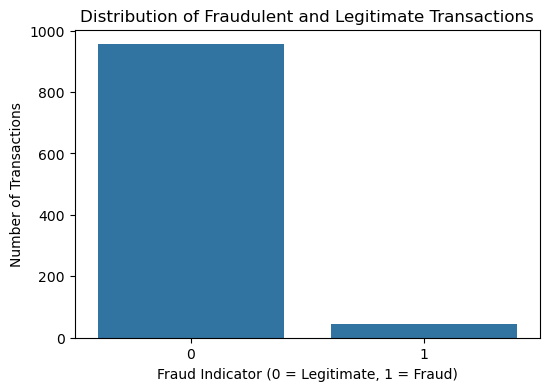

In [150]:
plt.figure(figsize=(6,4))
sns.countplot(x='FraudIndicator', data=df)
plt.title('Distribution of Fraudulent and Legitimate Transactions')
plt.xlabel('Fraud Indicator (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

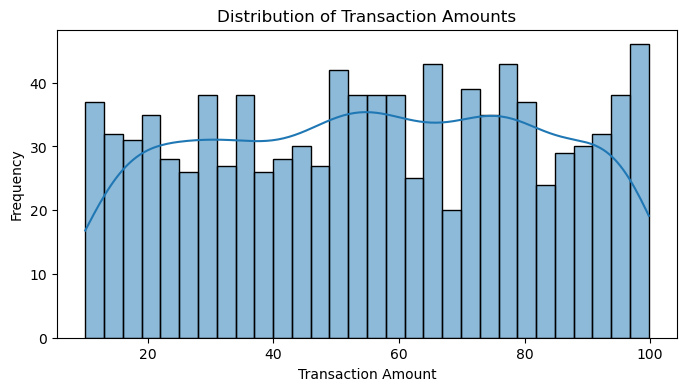

In [151]:
plt.figure(figsize=(8,4))
sns.histplot(data=df, x='TransactionAmount', bins=30, kde=True)
plt.title('Distribution of Transaction Amounts')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')
plt.show()

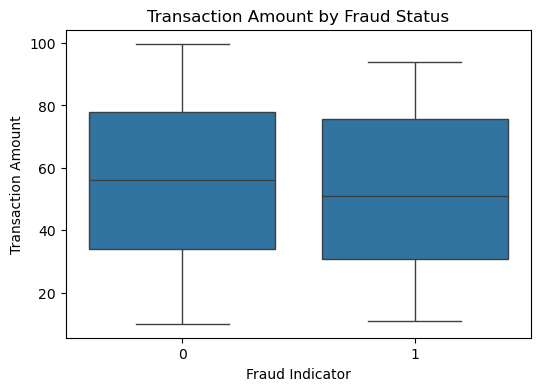

In [152]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='FraudIndicator', y='TransactionAmount')
plt.title('Transaction Amount by Fraud Status')
plt.xlabel('Fraud Indicator') 
plt.ylabel('Transaction Amount')
plt.show()

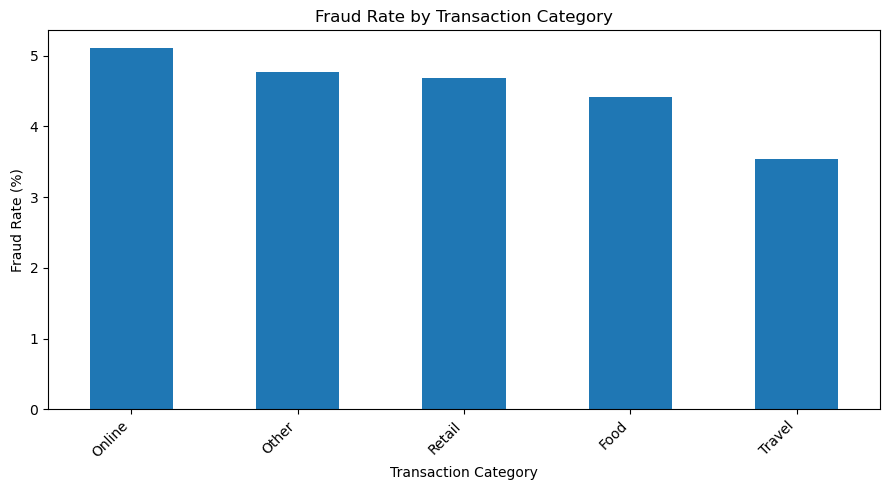

In [153]:
fraud_rate = df.groupby('Category')['FraudIndicator'].mean() * 100
fraud_rate.sort_values(ascending=False).plot(kind='bar', figsize=(9,5))
plt.title('Fraud Rate by Transaction Category')
plt.xlabel('Transaction Category')
plt.ylabel('Fraud Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## FEATURE ENGINEERING

In [154]:
encoders = {}

for column in df:
    label_encoder = LabelEncoder()
    df[column] = label_encoder.fit_transform(df[column])
    encoders[column] = label_encoder

C:\Users\HP\AppData\Local\Temp\ipykernel_21168\3065592850.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = label_encoder.fit_transform(df[column])
C:\Users\HP\AppData\Local\Temp\ipykernel_21168\3065592850.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[column] = label_encoder.fit_transform(df[column])
C:\Users\HP\AppData\Local\Temp\ipykernel_21168\3065592850.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col

In [155]:
df_ml = df.copy()

In [156]:
df


,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,MerchantName,Location,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag,TransactionHour,TransactionDay,TransactionMonth
0,0,0,2,768,694,0,446,475,597,446,446,597,32,597,115,597,0,0,5,0
2,913,0,2,930,865,913,446,966,6,446,446,6,14,6,293,6,0,1,1,1
4,293,0,2,77,412,293,157,254,6,157,157,6,14,6,293,6,0,5,3,0
6,343,0,2,371,349,343,147,847,281,147,147,281,1,281,43,281,0,7,5,0
7,593,0,2,1,132,593,107,117,512,107,107,512,15,512,303,512,0,17,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017,217,0,1,130,96,217,571,844,246,571,571,246,13,246,69,246,1,1,0,0
2018,228,0,2,919,258,228,440,165,251,440,440,251,14,251,221,251,1,12,0,0
2019,270,1,2,8,623,270,388,266,279,388,388,279,18,279,325,279,1,6,2,0
2020,601,0,3,199,330,601,245,695,368,245,245,368,17,368,513,368,1,1,2,0


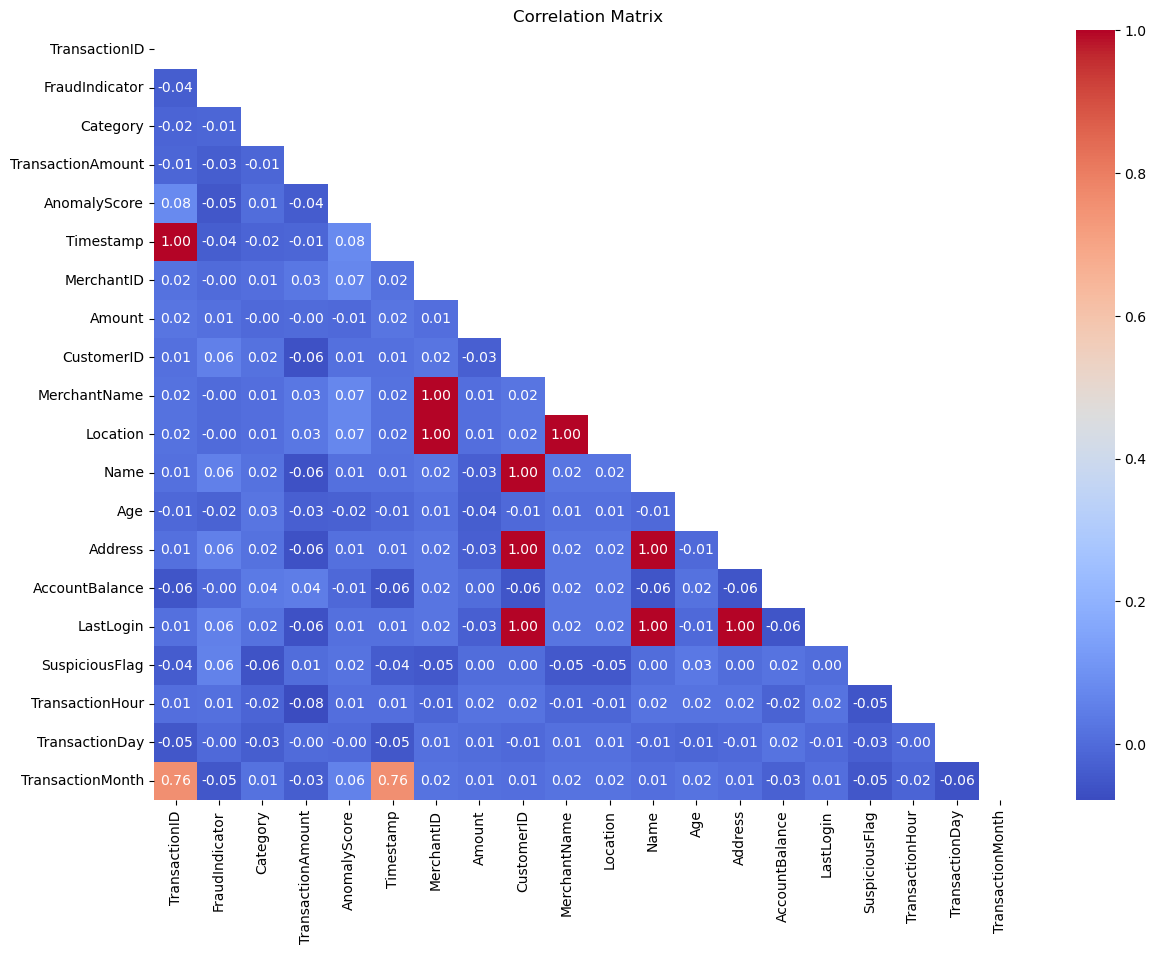

In [157]:
plt.figure(figsize = (14, 10))
cut_upper = np.triu(df.corr())
sns.heatmap(df.corr(), annot=True, cmap = "coolwarm", fmt = ".2f", mask = cut_upper)
plt.title("Correlation Matrix")
plt.show()

In [158]:
df_ml[["Amount","TransactionAmount"]].describe()

,Amount,TransactionAmount
count,1000.000000,1000.000000
mean,499.500000,499.500000
std,288.819436,288.819436
min,0.000000,0.000000
25%,249.750000,249.750000
50%,499.500000,499.500000
75%,749.250000,749.250000
max,999.000000,999.000000


In [159]:
(df_ml["Amount"] == df_ml["TransactionAmount"]).all()
 

np.False_

In [160]:
df_ml.loc[df_ml["Amount"] != df_ml["TransactionAmount"], ["Amount", "TransactionAmount"]].head(10)

,Amount,TransactionAmount
0,475,768
2,966,930
4,254,77
6,847,371
7,117,1
11,377,290
13,13,827
15,124,324
21,778,472
22,826,811


In [161]:
df_ml[["Amount", "TransactionAmount"]].corr()

,Amount,TransactionAmount
Amount,1.000000,-0.002065
TransactionAmount,-0.002065,1.000000


In [162]:
columns_to_drop = ["TransactionID", "CustomerID", "MerchantID", "Name", "Address", "MerchantName", "LastLogin"]
df_ml = df_ml.drop(columns=columns_to_drop, errors="ignore")
df_ml.head()

,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,Amount,Location,Age,AccountBalance,SuspiciousFlag,TransactionHour,TransactionDay,TransactionMonth
0,0,2,768,694,0,475,446,32,115,0,0,5,0
2,0,2,930,865,913,966,446,14,293,0,1,1,1
4,0,2,77,412,293,254,157,14,293,0,5,3,0
6,0,2,371,349,343,847,147,1,43,0,7,5,0
7,0,2,1,132,593,117,107,15,303,0,17,1,0


In [163]:
X= df_ml.drop(columns=["FraudIndicator"])
y= df_ml["FraudIndicator"]

In [164]:
X

,Category,TransactionAmount,AnomalyScore,Timestamp,Amount,Location,Age,AccountBalance,SuspiciousFlag,TransactionHour,TransactionDay,TransactionMonth
0,2,768,694,0,475,446,32,115,0,0,5,0
2,2,930,865,913,966,446,14,293,0,1,1,1
4,2,77,412,293,254,157,14,293,0,5,3,0
6,2,371,349,343,847,147,1,43,0,7,5,0
7,2,1,132,593,117,107,15,303,0,17,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2017,1,130,96,217,844,571,13,69,1,1,0,0
2018,2,919,258,228,165,440,14,221,1,12,0,0
2019,2,8,623,270,266,388,18,325,1,6,2,0
2020,3,199,330,601,695,245,17,513,1,1,2,0


In [165]:
print(y.value_counts())
print("\nPercentage distribution:")
print(y.value_counts(normalize=True) * 100)

FraudIndicator
0    955
1     45
Name: count, dtype: int64

Percentage distribution:
FraudIndicator
0    95.5
1     4.5
Name: proportion, dtype: float64


## SPLIT DATASET

In [166]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.9, random_state = 42, stratify=y)

## TRAIN MODEL

In [167]:
lr_model = LogisticRegression(max_iter=5000, random_state=42)

# Train model
lr_model.fit(X_train, y_train)

# Predictions
lr_pred = lr_model.predict(X_test)

# Evaluation
print("========== Logistic Regression ==========")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred))
print("Recall Score:", recall_score(y_test, lr_pred))
print("F1 Score:", f1_score(y_test, lr_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, lr_pred))

print("\nClassification Report")
print(classification_report(y_test, lr_pred))


========== Logistic Regression ==========
Accuracy: 0.9444444444444444
Precision: 0.0
Recall Score: 0.0
F1 Score: 0.0

Confusion Matrix
[[850  10]
 [ 40   0]]

Classification Report
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       860
           1       0.00      0.00      0.00        40

    accuracy                           0.94       900
   macro avg       0.48      0.49      0.49       900
weighted avg       0.91      0.94      0.93       900



In [168]:
rf_model = RandomForestClassifier(random_state=42)

# Train model
rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)

# Evaluation
print("========== Random Forest ==========")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall Score:", recall_score(y_test, rf_pred))
print("F1 Score:", f1_score(y_test, rf_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report")
print(classification_report(y_test, rf_pred))

========== Random Forest ==========
Accuracy: 0.9533333333333334
Precision: 0.0
Recall Score: 0.0
F1 Score: 0.0

Confusion Matrix
[[858   2]
 [ 40   0]]

Classification Report
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       860
           1       0.00      0.00      0.00        40

    accuracy                           0.95       900
   macro avg       0.48      0.50      0.49       900
weighted avg       0.91      0.95      0.93       900



In [169]:
xgb_model = XGBClassifier(random_state=42)

# Train model
xgb_model.fit(X_train, y_train)

# Predictions
xgb_pred = xgb_model.predict(X_test)

# Evaluation
print("========== XGBoost ==========")
print("Accuracy:", accuracy_score(y_test, xgb_pred))
print("Precision:", precision_score(y_test, xgb_pred))
print("Recall Score:", recall_score(y_test, xgb_pred))
print("F1 Score:", f1_score(y_test, xgb_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, xgb_pred))

print("\nClassification Report")
print(classification_report(y_test, xgb_pred))

========== XGBoost ==========
Accuracy: 0.9522222222222222
Precision: 0.2
Recall Score: 0.025
F1 Score: 0.044444444444444446

Confusion Matrix
[[856   4]
 [ 39   1]]

Classification Report
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       860
           1       0.20      0.03      0.04        40

    accuracy                           0.95       900
   macro avg       0.58      0.51      0.51       900
weighted avg       0.92      0.95      0.93       900



**SAVE MODEL**

**CONCLUSION**